# Dataset Exploration

This notebook explores the Amazon Electronics metadata dataset and examines the relationship between the review dataset and the product metadata. The aim is to understand the available product attributes, assess their quality, identify missing values, and determine which metadata features are suitable for constructing metadata-enhanced Graph Neural Network recommendation models.

## 1. Imports

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
pd.set_option("display.max_columns", None)

## 2. File paths

In [ ]:
RAW_DIR = Path("../data/raw")

REVIEWS_PATH = RAW_DIR / "Electronics.jsonl.gz"
META_PATH = RAW_DIR / "meta_Electronics.jsonl.gz"

## 3. Load a Sample (initial inspection of both datasets)

In [ ]:
reviews = pd.read_json(
    REVIEWS_PATH,
    lines=True,
    compression="gzip",
    nrows=5
)

metadata = pd.read_json(
    META_PATH,
    lines=True,
    compression="gzip",
    nrows=5
)

In [5]:
print(reviews.shape)

reviews.head()

(5, 10)


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,3,Smells like gasoline! Going back!,First & most offensive: they reek of gasoline ...,[{'small_image_url': 'https://m.media-amazon.c...,B083NRGZMM,B083NRGZMM,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,2022-07-18 22:58:37.948,0,True
1,1,Didn’t work at all lenses loose/broken.,These didn’t work. Idk if they were damaged in...,[],B07N69T6TM,B07N69T6TM,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,2020-06-20 18:42:29.731,0,True
2,5,Excellent!,I love these. They even come with a carry case...,[],B01G8JO5F2,B01G8JO5F2,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,2018-04-07 09:23:37.534,0,True
3,5,Great laptop backpack!,I was searching for a sturdy backpack for scho...,[],B001OC5JKY,B001OC5JKY,AGGZ357AO26RQZVRLGU4D4N52DZQ,2010-11-20 18:41:35.000,18,True
4,5,Best Headphones in the Fifties price range!,I've bought these headphones three times becau...,[],B013J7WUGC,B07CJYMRWM,AG2L7H23R5LLKDKLBEF2Q3L2MVDA,2023-02-17 02:39:41.238,0,True


In [6]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   rating             5 non-null      int64         
 1   title              5 non-null      str           
 2   text               5 non-null      str           
 3   images             5 non-null      object        
 4   asin               5 non-null      str           
 5   parent_asin        5 non-null      str           
 6   user_id            5 non-null      str           
 7   timestamp          5 non-null      datetime64[ms]
 8   helpful_vote       5 non-null      int64         
 9   verified_purchase  5 non-null      bool          
dtypes: bool(1), datetime64[ms](1), int64(2), object(1), str(5)
memory usage: 497.0+ bytes


In [7]:
print(metadata.shape)

metadata.head()

(5, 14)


,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together
0,All Electronics,FS-1051 FATSHARK TELEPORTER V3 HEADSET,3.5,6,[],[Teleporter V3 The “Teleporter V3” kit sets a ...,NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],Fat Shark,"[Electronics, Television & Video, Video Glasses]","{'Date First Available': 'August 2, 2014', 'Ma...",B00MCW7G9M,NaN
1,All Electronics,Ce-H22B12-S1 4Kx2K Hdmi 4Port,5.0,1,"[UPC: 662774021904, Weight: 0.600 lbs]",[HDMI In - HDMI Out],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],SIIG,"[Electronics, Television & Video, Accessories,...",{'Product Dimensions': '0.83 x 4.17 x 2.05 inc...,B00YT6XQSE,NaN
2,Computers,Digi-Tatoo Decal Skin Compatible With MacBook ...,4.5,246,[WARNING: Please IDENTIFY MODEL NUMBER on the ...,[],19.99,[{'thumb': 'https://m.media-amazon.com/images/...,"[{'title': 'AL 2Sides Video', 'url': 'https://...",Digi-Tatoo,"[Electronics, Computers & Accessories, Laptop ...","{'Brand': 'Digi-Tatoo', 'Color': 'Fresh Marble...",B07SM135LS,NaN
3,AMAZON FASHION,NotoCity Compatible with Vivoactive 4 band 22m...,4.5,233,[☛NotoCity 22mm band is designed for Vivoactiv...,[],9.99,[{'thumb': 'https://m.media-amazon.com/images/...,[],NotoCity,"[Electronics, Wearable Technology, Clips, Arm ...","{'Date First Available': 'May 29, 2020', 'Manu...",B089CNGZCW,NaN
4,Cell Phones & Accessories,Motorola Droid X Essentials Combo Pack,3.8,64,"[New Droid X Essentials Combo Pack, Exclusive ...",[all Genuine High Quality Motorola Made Access...,14.99,[{'thumb': 'https://m.media-amazon.com/images/...,[],Verizon,"[Electronics, Computers & Accessories, Compute...",{'Product Dimensions': '11.6 x 6.9 x 3.1 inche...,B004E2Z88O,NaN


In [8]:
metadata.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   main_category    5 non-null      str    
 1   title            5 non-null      str    
 2   average_rating   5 non-null      float64
 3   rating_number    5 non-null      int64  
 4   features         5 non-null      object 
 5   description      5 non-null      object 
 6   price            3 non-null      float64
 7   images           5 non-null      object 
 8   videos           5 non-null      object 
 9   store            5 non-null      str    
 10  categories       5 non-null      object 
 11  details          5 non-null      object 
 12  parent_asin      5 non-null      str    
 13  bought_together  0 non-null      float64
dtypes: float64(3), int64(1), object(6), str(4)
memory usage: 692.0+ bytes


In [12]:
print(reviews.columns.tolist())
print(f"Review columns: {len(reviews.columns)}")
print("-----")

print(metadata.columns.tolist())
print(f"Metadata columns: {len(metadata.columns)}")

['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']
Review columns: 10
-----
['main_category', 'title', 'average_rating', 'rating_number', 'features', 'description', 'price', 'images', 'videos', 'store', 'categories', 'details', 'parent_asin', 'bought_together']
Metadata columns: 14


# 4. Metadata Dataset

## 4.1 Metadata Column Overview

| Column | Description | Potential Use |
|---------|-------------|---------------|
| `main_category` | High-level product category | Category feature |
| `title` | Product title | Text feature |
| `average_rating` | Average product rating | Descriptive analysis |
| `rating_number` | Number of ratings | Popularity analysis |
| `features` | Product features | Optional text feature |
| `description` | Product description | Optional text feature |
| `price` | Product price | Numerical feature |
| `images` | Product images | Not used |
| `videos` | Product videos | Not used |
| `store` | Brand or seller | Metadata feature |
| `categories` | Product category hierarchy | Metadata feature |
| `details` | Product specifications | Optional metadata feature |
| `parent_asin` | Product identifier | Used to merge with review data |
| `bought_together` | Frequently bought together products | Future work / not used |

The metadata dataset contains product-level information that can be used to enrich the graph representation of items. Features such as the product title, store, categories, and price may provide additional information beyond user–item interactions, while fields such as images and videos are not considered in this project.

## 4.2 Loading the Metadata dataset

In [13]:
metadata_size_gb = META_PATH.stat().st_size / (1024 ** 3)
reviews_size_gb = REVIEWS_PATH.stat().st_size / (1024 ** 3)

print(f"Compressed reviews file size: {reviews_size_gb:.2f} GB")
print(f"Compressed metadata file size: {metadata_size_gb:.2f} GB")

Compressed reviews file size: 6.03 GB
Compressed metadata file size: 1.22 GB


In [14]:
import gzip
import json
import pickle
import time

from collections import Counter
from pathlib import Path

In [15]:
PROCESSED_DIR = Path("../data/processed")
METADATA_CACHE_FILE = PROCESSED_DIR / "metadata_exploration.pkl"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

In [16]:
METADATA_FIELDS = [
    "main_category",
    "title",
    "average_rating",
    "rating_number",
    "features",
    "description",
    "price",
    "images",
    "videos",
    "store",
    "categories",
    "details",
    "parent_asin",
    "bought_together",
]

In [17]:
if METADATA_CACHE_FILE.exists():
    print("Cached metadata exploration results found. Loading...")

    with open(METADATA_CACHE_FILE, "rb") as file:
        metadata_stats = pickle.load(file)

    print("Metadata exploration results loaded successfully.")

else:
    print("No cached metadata results found.")
    print("Scanning the full metadata dataset...")

    total_products = 0
    missing_counts = Counter()

    store_counts = Counter()
    main_category_counts = Counter()

    seen_parent_asins = set()
    duplicate_parent_asins = 0

    valid_price_count = 0
    price_sum = 0.0
    price_min = None
    price_max = None
    prices = []

    start_time = time.time()

    with gzip.open(META_PATH, "rt", encoding="utf-8") as file:
        for line in file:
            product = json.loads(line)
            total_products += 1

            # Missing values
            for field in METADATA_FIELDS:
                value = product.get(field)

                if value is None or value == "" or value == [] or value == {}:
                    missing_counts[field] += 1

            # Duplicate product identifiers
            parent_asin = product.get("parent_asin")

            if parent_asin:
                if parent_asin in seen_parent_asins:
                    duplicate_parent_asins += 1
                else:
                    seen_parent_asins.add(parent_asin)

            # Store frequency
            store = product.get("store")

            if store:
                store_counts[store] += 1

            # Main-category frequency
            main_category = product.get("main_category")

            if main_category:
                main_category_counts[main_category] += 1

            # Price statistics
            price = product.get("price")

            if isinstance(price, (int, float)):
                price = float(price)

                valid_price_count += 1
                price_sum += price
                prices.append(price)

                if price_min is None or price < price_min:
                    price_min = price

                if price_max is None or price > price_max:
                    price_max = price

            # Progress
            if total_products % 100_000 == 0:
                elapsed = time.time() - start_time
                speed = total_products / elapsed

                print(
                    f"Processed {total_products:,} products "
                    f"| {speed:,.0f} products/second "
                    f"| {elapsed / 60:.1f} minutes"
                )

    elapsed = time.time() - start_time

    metadata_stats = {
        "total_products": total_products,
        "missing_counts": missing_counts,
        "store_counts": store_counts,
        "main_category_counts": main_category_counts,
        "unique_parent_asins": seen_parent_asins,
        "duplicate_parent_asins": duplicate_parent_asins,
        "valid_price_count": valid_price_count,
        "price_sum": price_sum,
        "price_min": price_min,
        "price_max": price_max,
        "prices": prices,
    }

    with open(METADATA_CACHE_FILE, "wb") as file:
        pickle.dump(
            metadata_stats,
            file,
            protocol=pickle.HIGHEST_PROTOCOL
        )

    print("\nMetadata scan completed.")
    print(f"Elapsed time: {elapsed / 60:.2f} minutes")
    print(f"Results saved to: {METADATA_CACHE_FILE}")

No cached metadata results found.
Scanning the full metadata dataset...
Processed 100,000 products | 33,552 products/second | 0.0 minutes
Processed 200,000 products | 35,667 products/second | 0.1 minutes
Processed 300,000 products | 36,204 products/second | 0.1 minutes
Processed 400,000 products | 36,706 products/second | 0.2 minutes
Processed 500,000 products | 37,151 products/second | 0.2 minutes
Processed 600,000 products | 37,467 products/second | 0.3 minutes
Processed 700,000 products | 37,741 products/second | 0.3 minutes
Processed 800,000 products | 38,043 products/second | 0.4 minutes
Processed 900,000 products | 38,241 products/second | 0.4 minutes
Processed 1,000,000 products | 38,451 products/second | 0.4 minutes
Processed 1,100,000 products | 38,601 products/second | 0.5 minutes
Processed 1,200,000 products | 38,823 products/second | 0.5 minutes
Processed 1,300,000 products | 39,162 products/second | 0.6 minutes
Processed 1,400,000 products | 39,516 products/second | 0.6 mi

In [19]:
total_products = metadata_stats["total_products"]
missing_counts = metadata_stats["missing_counts"]
store_counts = metadata_stats["store_counts"]
main_category_counts = metadata_stats["main_category_counts"]
metadata_products = metadata_stats["unique_parent_asins"]
duplicate_parent_asins = metadata_stats["duplicate_parent_asins"]
valid_price_count = metadata_stats["valid_price_count"]
price_sum = metadata_stats["price_sum"]
price_min = metadata_stats["price_min"]
price_max = metadata_stats["price_max"]
prices = metadata_stats["prices"]

## 4.3 Missing Value Analysis

This section examines the completeness of each metadata attribute. Both missing-value counts and percentages are reported to help identify which product features are sufficiently complete for use in the recommendation system.

In [20]:
missing_summary = pd.DataFrame({
    "Missing Values": {
        field: missing_counts.get(field, 0)
        for field in METADATA_FIELDS
    }
})

missing_summary["Missing Percentage (%)"] = (
    missing_summary["Missing Values"] / total_products * 100
).round(2)

missing_summary = missing_summary.sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

missing_summary

,Missing Values,Missing Percentage (%)
bought_together,1610012,100.00
videos,1209607,75.13
price,1083247,67.28
description,682748,42.41
features,423041,26.28
categories,128442,7.98
main_category,106334,6.60
details,21139,1.31
store,9522,0.59
images,369,0.02


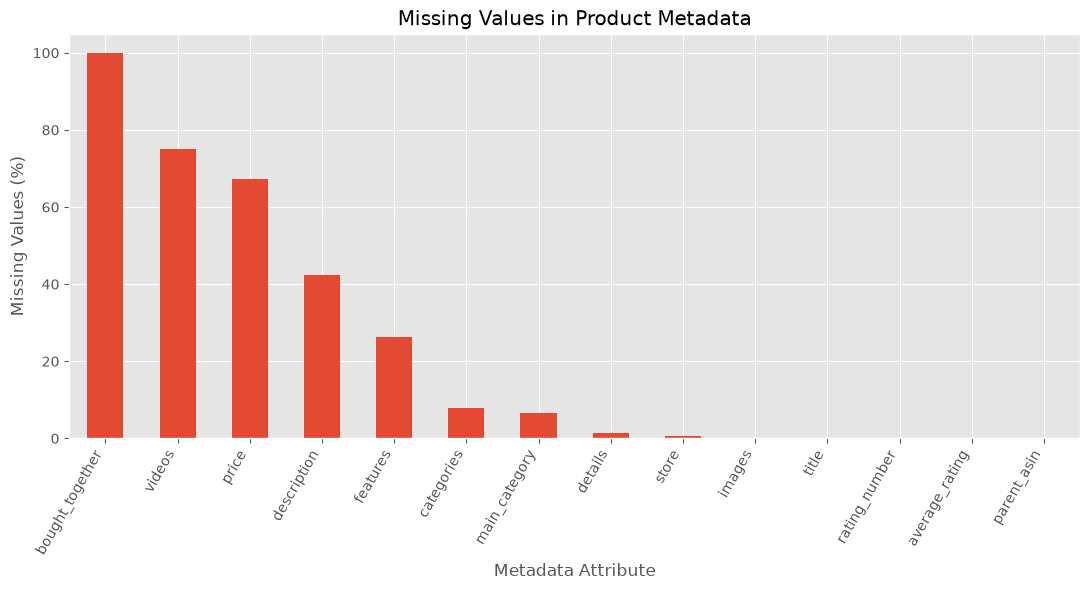

In [21]:
plt.figure(figsize=(11, 6))

missing_summary["Missing Percentage (%)"].plot(kind="bar")

plt.title("Missing Values in Product Metadata")
plt.xlabel("Metadata Attribute")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

## 4.4 Duplicate Product Analysis

Each metadata record should ideally correspond to a unique product identified by `parent_asin`. Duplicate identifiers may cause ambiguity when product metadata is merged with review interactions.

In [ ]:
metadata_size_gb = META_PATH.stat().st_size / (1024 ** 3)
reviews_size_gb = REVIEWS_PATH.stat().st_size / (1024 ** 3)

print(f"Compressed reviews file size: {reviews_size_gb:.2f} GB")
print(f"Compressed metadata file size: {metadata_size_gb:.2f} GB")

Compressed reviews file size: 6.03 GB
Compressed metadata file size: 1.22 GB


In [24]:
unique_product_count = len(metadata_products)

print(f"Total metadata records: {total_products:,}")
print(f"Unique parent_asin values: {unique_product_count:,}")
print(f"Duplicate parent_asin records: {duplicate_parent_asins:,}")

duplicate_percentage = (
    duplicate_parent_asins / total_products * 100
    if total_products > 0
    else 0
)

print(f"Duplicate record percentage: {duplicate_percentage:.4f}%")

Total metadata records: 1,610,012
Unique parent_asin values: 1,610,012
Duplicate parent_asin records: 0
Duplicate record percentage: 0.0000%


## 4.5 Store Analysis

The `store` attribute provides information about the brand, seller, or product store associated with each item. This section examines the number of unique store values and the most frequently represented stores in the dataset.

In [25]:
unique_stores = len(store_counts)

print(f"Unique non-missing stores: {unique_stores:,}")
print(
    f"Products with a store value: "
    f"{sum(store_counts.values()):,}"
)

Unique non-missing stores: 142,185
Products with a store value: 1,600,490


In [26]:
# Top 20 Stores

top_stores = pd.Series(
    dict(store_counts.most_common(20)),
    name="Product Count"
)

top_stores

Amazon Renewed     30576
HP                 17129
Sony               14160
Generic            13499
SAMSUNG            11503
Lenovo              9049
Dell                7042
ASUS                6870
Neewer              6755
Fintie              5370
Canon               5125
UPBRIGHT            4574
uxcell              4386
Panasonic           4039
Kastar              3679
Garmin              3608
Belkin              3343
Synergy Digital     3148
Nikon               3116
HQRP                3074
Name: Product Count, dtype: int64

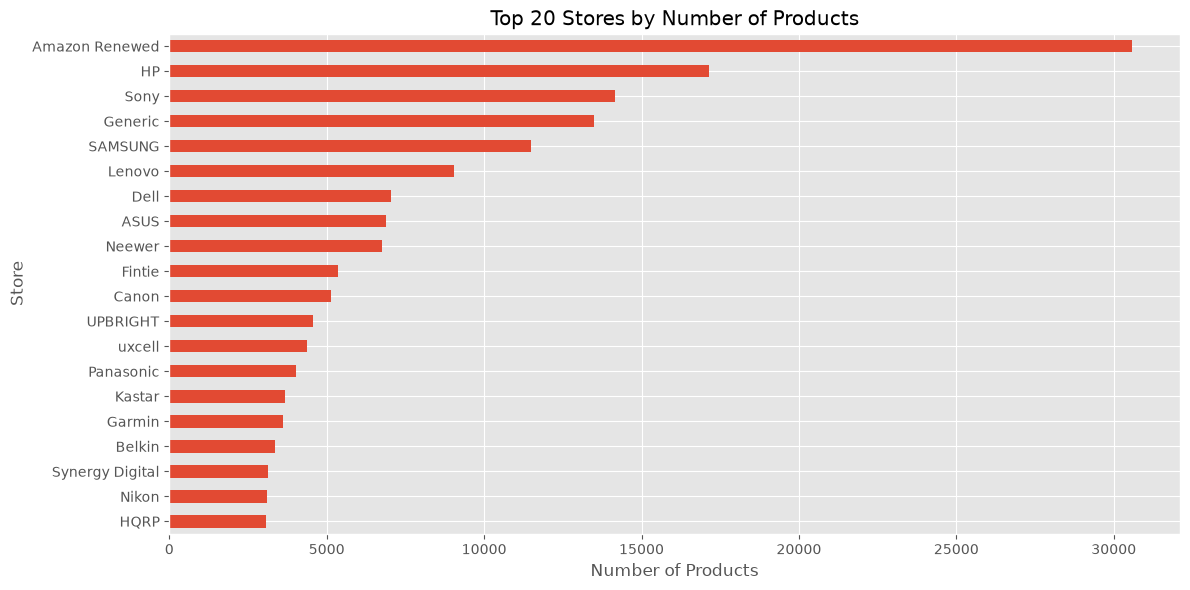

In [27]:
plt.figure(figsize=(12, 6))

top_stores.sort_values().plot(kind="barh")

plt.title("Top 20 Stores by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Store")
plt.tight_layout()
plt.show()

## 4.6 Main Category Analysis

The `main_category` field describes the broad category assigned to each product. Examining this distribution helps determine whether the Electronics dataset contains products from several related Amazon departments.

In [28]:
category_summary = pd.Series(
    main_category_counts,
    name="Product Count"
).sort_values(ascending=False)

print(f"Unique non-missing main categories: {len(category_summary):,}")

category_summary

Unique non-missing main categories: 42


Computers                       418868
All Electronics                 376435
Camera & Photo                  223690
Cell Phones & Accessories       138237
Home Audio & Theater            106516
Industrial & Scientific          50555
Car Electronics                  27332
Tools & Home Improvement         24042
Amazon Home                      21299
Office Products                  21250
AMAZON FASHION                   18391
Sports & Outdoors                14581
Automotive                       13956
GPS & Navigation                  9339
Amazon Devices                    8484
Portable Audio & Accessories      8050
Musical Instruments               6668
Toys & Games                      3944
Health & Personal Care            3073
All Beauty                        1848
Arts, Crafts & Sewing             1496
Apple Products                    1078
Video Games                       1042
Books                              994
Baby                               797
Pet Supplies             

In [29]:
category_table = category_summary.to_frame()

category_table["Percentage (%)"] = (
    category_table["Product Count"] / total_products * 100
).round(2)

category_table

,Product Count,Percentage (%)
Computers,418868,26.02
All Electronics,376435,23.38
Camera & Photo,223690,13.89
Cell Phones & Accessories,138237,8.59
Home Audio & Theater,106516,6.62
Industrial & Scientific,50555,3.14
Car Electronics,27332,1.70
Tools & Home Improvement,24042,1.49
Amazon Home,21299,1.32
Office Products,21250,1.32


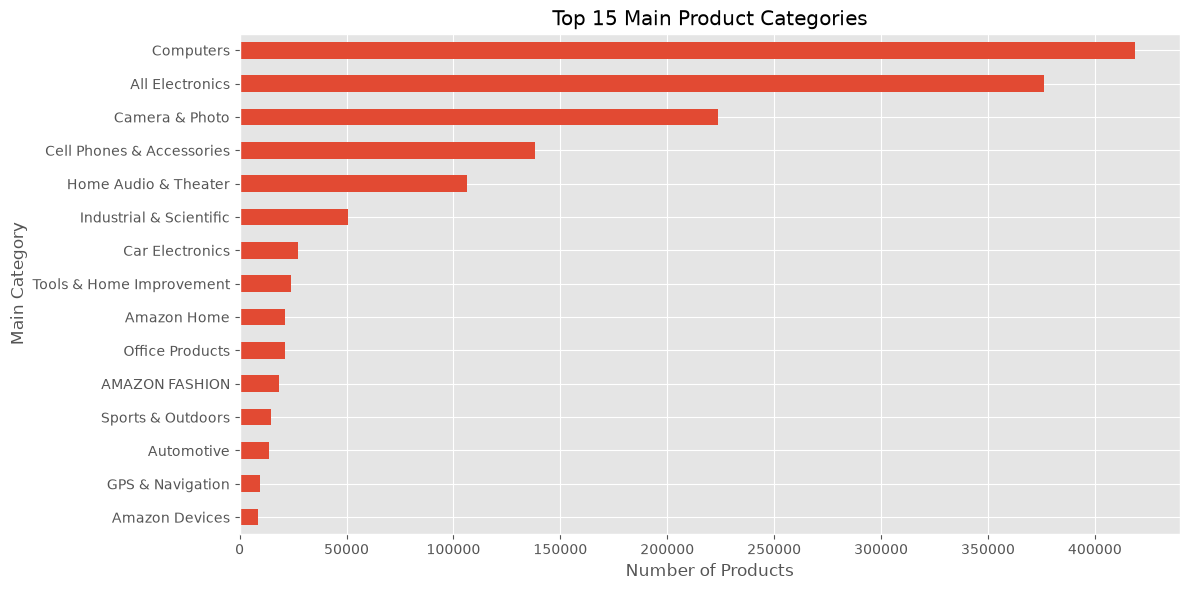

In [30]:
top_categories = category_summary.head(15)

plt.figure(figsize=(12, 6))
top_categories.sort_values().plot(kind="barh")

plt.title("Top 15 Main Product Categories")
plt.xlabel("Number of Products")
plt.ylabel("Main Category")
plt.tight_layout()
plt.show()

## 4.7 Price Analysis

Price is a numerical product attribute that may be useful as an item feature. This section examines its availability and basic distribution. The analysis is based only on valid numerical price values.

In [32]:
missing_price_count = missing_counts.get("price", 0)

average_price = (
    price_sum / valid_price_count
    if valid_price_count > 0
    else np.nan
)

price_series = pd.Series(prices, dtype="float64")

price_summary = pd.Series({
    "Total Products": total_products,
    "Products With Valid Price": valid_price_count,
    "Products Without Valid Price": missing_price_count,
    "Price Coverage (%)": round(
        valid_price_count / total_products * 100,
        2
    ),
    "Minimum Price": price_min,
    "Maximum Price": price_max,
    "Mean Price": average_price,
    "Median Price": (
        price_series.median()
        if not price_series.empty
        else np.nan
    ),
    "Standard Deviation": (
        price_series.std()
        if not price_series.empty
        else np.nan
    ),
})

price_summary = price_summary.map(
    lambda x: f"{x:,.2f}" if isinstance(x, (int, float, np.number)) else x
)

price_summary

Total Products                  1,610,012.00
Products With Valid Price         526,449.00
Products Without Valid Price    1,083,247.00
Price Coverage (%)                     32.70
Minimum Price                           0.00
Maximum Price                      44,630.00
Mean Price                             96.46
Median Price                           22.90
Standard Deviation                    319.17
dtype: str

## 4.8 Metadata Coverage

The review and metadata datasets are linked through the `parent_asin` product identifier. This analysis measures how many products appearing in the review interactions have a corresponding metadata record. Metadata coverage is important because only matched products can receive metadata-based node features.

In [33]:
# load notebook 1 cache

REVIEWS_CACHE_FILE = PROCESSED_DIR / "dataset_statistics.pkl"

with open(REVIEWS_CACHE_FILE, "rb") as file:
    review_statistics = pickle.load(file)

product_activity = review_statistics["product_activity"]

review_products = set(product_activity.keys())

## 4.8.1 Product level coverage

How many distinct products appearing in the reviews have a metadata record. This is the
figure that determines whether every item can receive a feature vector.


In [34]:
matched_products = review_products.intersection(metadata_products)
products_without_metadata = review_products.difference(metadata_products)

product_coverage = (
    len(matched_products) / len(review_products)
    if review_products
    else 0
)

print(f"Unique reviewed products: {len(review_products):,}")
print(f"Reviewed products with metadata: {len(matched_products):,}")
print(
    f"Reviewed products without metadata: "
    f"{len(products_without_metadata):,}"
)
print(f"Product-level metadata coverage: {product_coverage:.2%}")

Unique reviewed products: 1,609,860
Reviewed products with metadata: 1,609,860
Reviewed products without metadata: 0
Product-level metadata coverage: 100.00%


## 4.8.2 Interaction-level coverage

The same question weighted by how often each product is reviewed. Product-level and
interaction-level coverage can differ substantially: a handful of missing popular products
would matter far more than a long tail of missing rare ones.

In [35]:
matched_interactions = sum(
    interaction_count
    for product_id, interaction_count in product_activity.items()
    if product_id in metadata_products
)

total_interactions = sum(product_activity.values())

unmatched_interactions = total_interactions - matched_interactions

interaction_coverage = (
    matched_interactions / total_interactions
    if total_interactions > 0
    else 0
)

print(f"Total review interactions: {total_interactions:,}")
print(
    f"Interactions linked to product metadata: "
    f"{matched_interactions:,}"
)
print(
    f"Interactions without product metadata: "
    f"{unmatched_interactions:,}"
)
print(
    f"Interaction-level metadata coverage: "
    f"{interaction_coverage:.2%}"
)

Total review interactions: 43,886,944
Interactions linked to product metadata: 43,886,944
Interactions without product metadata: 0
Interaction-level metadata coverage: 100.00%


## 4.8.3 Coverage Summary


In [37]:
coverage_summary = pd.DataFrame({
    "Measure": [
        "Reviewed products",
        "Reviewed products with metadata",
        "Reviewed products without metadata",
        "Total review interactions",
        "Interactions with metadata",
        "Interactions without metadata",
    ],
    "Count": [
        len(review_products),
        len(matched_products),
        len(products_without_metadata),
        total_interactions,
        matched_interactions,
        unmatched_interactions,
    ],
    "Percentage": [
        "100.00%",
        f"{product_coverage:.2%}",
        f"{100 - product_coverage*100:.2f}%",
        "100.00%",
        f"{interaction_coverage:.2%}",
        f"{100 - interaction_coverage*100:.2f}%",
    ]
})

coverage_summary

,Measure,Count,Percentage
0,Reviewed products,1609860,100.00%
1,Reviewed products with metadata,1609860,100.00%
2,Reviewed products without metadata,0,0.00%
3,Total review interactions,43886944,100.00%
4,Interactions with metadata,43886944,100.00%
5,Interactions without metadata,0,0.00%


# Metadata Feature Selection

Based on the exploration performed in this notebook, the available metadata attributes were evaluated according to their completeness, relevance, and suitability for metadata-enhanced recommendation modelling.

The `parent_asin` field will be retained as the primary identifier for linking review interactions with product metadata. Product-level descriptive attributes, including `title`, `store`, `main_category`, `categories`, `features`, `description`, and `details`, will also be retained as candidate metadata features. These attributes provide useful textual and categorical information that may enhance the representation of items within the recommendation graph. Although `features` and `description` contain some missing values, their coverage remains sufficient to justify further consideration during preprocessing.

The `price` attribute will not be included as a primary metadata feature because valid price information is available for only 32.7% of products. Incorporating this attribute would require extensive handling of missing values and could introduce unnecessary sparsity.

The `videos` and `bought_together` attributes will be excluded from further processing. The `videos` field contains a high proportion of missing values, while the `bought_together` field is entirely missing in the Electronics metadata dataset and therefore provides no useful information for this project.

The complete metadata coverage analysis showed that every reviewed product has a corresponding metadata record. Consequently, all user–item interactions can be enriched with product metadata during graph construction without discarding any review data.

**One caveat discovered later**: the `details` field contains a `Best Sellers Rank` entry,
present for 56.3% of products, which reflects popularity at the time the dataset was
collected rather than at the time of any interaction. Notebook 07 strips it before
encoding, since including it would leak post-cutoff information into the item features.